### Section 2: Create the sample (simulated) dataset - run this first

In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)

products = [
    ("P101", "Basmati Rice 5 kg", "Staples & Grocery", "Rice", "GoldenGrain", 620),
    ("P102", "Wheat Flour 5 kg", "Staples & Grocery", "Flour", "HarvestPure", 260),
    ("P103", "Toor Dal 1 kg", "Staples & Grocery", "Pulses", "GoldenGrain", 165),
    ("P104", "Sunflower Oil 1 L", "Staples & Grocery", "Edible Oil", "SunDrop", 145),
    ("P105", "Sugar 1 kg", "Staples & Grocery", "Sugar", "SweetLeaf", 48),
    ("P106", "Iodised Salt 1 kg", "Staples & Grocery", "Salt", "PureCrystal", 26),
    ("P107", "Tea Powder 500 g", "Staples & Grocery", "Tea", "MorningBrew", 240),
    ("P201", "Orange Juice 1 L", "Beverages", "Juices", "FruitFresh", 110),
    ("P202", "Mixed Fruit Juice 1 L", "Beverages", "Juices", "FruitFresh", 115),
    ("P203", "Cola 750 ml", "Beverages", "Soft Drinks", "FizzUp", 40),
    ("P204", "Lemon Soda 750 ml", "Beverages", "Soft Drinks", "FizzUp", 40),
    ("P205", "Packaged Water 1 L", "Beverages", "Water", "AquaPure", 20),
    ("P206", "Energy Drink 250 ml", "Beverages", "Energy Drinks", "VoltX", 110),
    ("P207", "Flavoured Milk 200 ml", "Beverages", "Milk Drinks", "CreamyCow", 30),
    ("P301", "Potato Chips 90 g", "Snacks & Confectionery", "Chips", "CrunchTime", 30),
    ("P302", "Instant Noodles 4-pack", "Snacks & Confectionery", "Noodles", "QuickBite", 60),
    ("P303", "Cream Biscuits 300 g", "Snacks & Confectionery", "Biscuits", "BakeJoy", 35),
    ("P304", "Milk Chocolate 50 g", "Snacks & Confectionery", "Chocolates", "ChocoDelight", 60),
    ("P305", "Chocolate Pouch 100 g", "Snacks & Confectionery", "Chocolates", "ChocoDelight", 120),
    ("P306", "Lollipop Pack", "Snacks & Confectionery", "Candies", "SweetPop", 50),
    ("P307", "Salted Namkeen 400 g", "Snacks & Confectionery", "Namkeen", "SnackHub", 110),
    ("P401", "Shampoo 340 ml", "Personal Care", "Hair Care", "SilkyLocks", 320),
    ("P402", "Conditioner 180 ml", "Personal Care", "Hair Care", "SilkyLocks", 250),
    ("P403", "Body Deodorant 150 ml", "Personal Care", "Deodorants", "ZestMan", 199),
    ("P404", "Face Wash 100 g", "Personal Care", "Skin Care", "GlowFresh", 140),
    ("P405", "Moisturising Lotion 400 ml", "Personal Care", "Skin Care", "SoftSkin", 280),
    ("P406", "Toothpaste 200 g", "Personal Care", "Oral Care", "BrightSmile", 110),
    ("P407", "Bathing Soap 3-pack", "Personal Care", "Soaps", "PureBath", 130),
    ("P501", "Detergent Powder 1 kg", "Home Care", "Laundry", "CleanWave", 130),
    ("P502", "Fabric Conditioner 1 L", "Home Care", "Laundry", "CleanWave", 230),
    ("P503", "Dishwash Liquid 500 ml", "Home Care", "Dishwash", "ShineAll", 110),
    ("P504", "Floor Cleaner 1 L", "Home Care", "Floor Care", "ShineAll", 190),
    ("P505", "Room Freshener 250 ml", "Home Care", "Air Care", "FreshAir", 220),
    ("P506", "Toilet Cleaner 500 ml", "Home Care", "Bathroom Care", "ShineAll", 105),
    ("P507", "Garbage Bags 30 pcs", "Home Care", "Disposables", "TidyHome", 90),
    ("P601", "Full Cream Milk 1 L", "Dairy & Bakery", "Milk", "CreamyCow", 68),
    ("P602", "Curd 400 g", "Dairy & Bakery", "Curd", "CreamyCow", 45),
    ("P603", "Butter 100 g", "Dairy & Bakery", "Butter", "CreamyCow", 62),
    ("P604", "Paneer 200 g", "Dairy & Bakery", "Paneer", "CreamyCow", 95),
    ("P605", "Bread Loaf", "Dairy & Bakery", "Bread", "BakeJoy", 45),
    ("P606", "Cheese Slices 200 g", "Dairy & Bakery", "Cheese", "CreamyCow", 140),
    ("P607", "Eggs (Dozen)", "Dairy & Bakery", "Eggs", "FarmFresh", 84),
]
prod = pd.DataFrame(products, columns=["Product_ID", "Product_Name", "Category",
                                       "Sub_Category", "Brand", "Unit_Price"])
prod["Stock_Available"] = np.random.randint(5, 150, len(prod))

n = 1200
wt = np.random.uniform(0.4, 2.0, len(prod)) / (prod["Unit_Price"] ** 0.3)
idx = np.random.choice(prod.index, size=n, p=wt / wt.sum())
data = prod.loc[idx].reset_index(drop=True)

dates = pd.date_range("2026-07-01", "2026-09-28")
dw = np.where(dates.dayofweek >= 5, 1.5, 1.0)
data["Date"] = np.random.choice(dates, size=n, p=dw / dw.sum())
data["Customer_Type"] = np.random.choice(["Regular", "Occasional", "Bulk Buyer"],
                                         size=n, p=[0.55, 0.33, 0.12])
data["Payment_Method"] = np.random.choice(["UPI", "Cash", "Card"],
                                          size=n, p=[0.48, 0.38, 0.14])
qty = np.random.poisson(1.2, n) + 1
data["Quantity"] = np.where(data["Customer_Type"] == "Bulk Buyer", qty * 3, qty)
data["Discount_Percent"] = np.random.choice([0, 0, 0, 5, 5, 10, 15], size=n).astype(float)
data = data.sort_values("Date").reset_index(drop=True)
data["Bill_ID"] = ["B" + str(1001 + i) for i in range(n)]
data["Record_Source"] = "Simulated"

# Introduce common data-quality problems for the cleaning exercise
raw = data.copy()
raw.loc[raw.sample(30, random_state=1).index, "Discount_Percent"] = np.nan
raw.loc[raw.sample(20, random_state=2).index, "Payment_Method"] = np.nan
i = raw.sample(40, random_state=3).index
raw.loc[i[:15], "Category"] = raw.loc[i[:15], "Category"].str.upper()
raw.loc[i[15:30], "Category"] = raw.loc[i[15:30], "Category"].str.lower()
raw.loc[i[30:], "Category"] = " " + raw.loc[i[30:], "Category"] + " "
raw.loc[raw.sample(5, random_state=4).index, "Quantity"] = -1
raw.loc[raw.sample(4, random_state=5).index, "Unit_Price"] = 0
raw = pd.concat([raw, raw.sample(15, random_state=6)])
raw = raw.sort_values("Bill_ID", kind="stable").reset_index(drop=True)
raw["Date"] = pd.to_datetime(raw["Date"]).dt.strftime("%d-%m-%Y")

cols = ["Bill_ID", "Product_ID", "Product_Name", "Category", "Sub_Category", "Brand",
        "Unit_Price", "Quantity", "Discount_Percent", "Date", "Payment_Method",
        "Customer_Type", "Stock_Available", "Record_Source"]
raw[cols].to_csv("../data/supermarket_sales_raw.csv", index=False)
print("Raw dataset saved:", raw.shape)

Raw dataset saved: (1215, 14)


/tmp/ipykernel_18221/3731864304.py:60: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dw = np.where(dates.dayofweek >= 5, 1.5, 1.0)


### Section 9: Data Loading - Importing libraries and loading the dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.width", 92)
pd.set_option("display.max_columns", 30)

df = pd.read_csv("../data/supermarket_sales_raw.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


### Section 9: Data Loading - Displaying the first 5 rows

In [3]:
print(df.head())

  Bill_ID Product_ID            Product_Name                Category Sub_Category  \
0   B1001       P302  Instant Noodles 4-pack  Snacks & Confectionery      Noodles   
1   B1002       P402      Conditioner 180 ml           Personal Care    Hair Care   
2   B1003       P104       Sunflower Oil 1 L       Staples & Grocery   Edible Oil   
3   B1004       P502  Fabric Conditioner 1 L               Home Care      Laundry   
4   B1005       P203             Cola 750 ml               Beverages  Soft Drinks   

        Brand  Unit_Price  Quantity  Discount_Percent        Date Payment_Method  \
0   QuickBite          60         2               0.0  01-07-2026           Cash   
1  SilkyLocks         250         2              15.0  01-07-2026           Card   
2     SunDrop         145         4               0.0  01-07-2026           Card   
3   CleanWave         230         2              15.0  01-07-2026            UPI   
4      FizzUp          40         3               0.0  01-07-2026    

### Section 9: Data Loading - Displaying the last 5 rows

In [4]:
print(df.tail())

     Bill_ID Product_ID            Product_Name                Category   Sub_Category  \
1210   B2196       P605              Bread Loaf          Dairy & Bakery          Bread   
1211   B2197       P302  Instant Noodles 4-pack  Snacks & Confectionery        Noodles   
1212   B2198       P206     Energy Drink 250 ml               Beverages  Energy Drinks   
1213   B2199       P201        Orange Juice 1 L               Beverages         Juices   
1214   B2200       P503  Dishwash Liquid 500 ml               Home Care       Dishwash   

           Brand  Unit_Price  Quantity  Discount_Percent        Date Payment_Method  \
1210     BakeJoy          45         3               5.0  28-09-2026           Card   
1211   QuickBite          60         6              15.0  28-09-2026            UPI   
1212       VoltX         110         2               0.0  28-09-2026            NaN   
1213  FruitFresh         110         2              10.0  28-09-2026           Cash   
1214    ShineAll        

### Section 9: Data Loading - Checking the shape of the dataset

In [5]:
print(df.shape)

(1215, 14)


### Section 9: Data Loading - Checking the column names

In [6]:
print(df.columns.tolist())

['Bill_ID', 'Product_ID', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Date', 'Payment_Method', 'Customer_Type', 'Stock_Available', 'Record_Source']


### Section 9: Data Loading - Checking the data types

In [7]:
print(df.dtypes)

Bill_ID                 str
Product_ID              str
Product_Name            str
Category                str
Sub_Category            str
Brand                   str
Unit_Price            int64
Quantity              int64
Discount_Percent    float64
Date                    str
Payment_Method          str
Customer_Type           str
Stock_Available       int64
Record_Source           str
dtype: object


### Section 9: Data Loading - Checking missing values

In [8]:
print(df.isnull().sum())

Bill_ID              0
Product_ID           0
Product_Name         0
Category             0
Sub_Category         0
Brand                0
Unit_Price           0
Quantity             0
Discount_Percent    30
Date                 0
Payment_Method      20
Customer_Type        0
Stock_Available      0
Record_Source        0
dtype: int64


### Section 8: Dataset Description - Number of rows and columns

In [9]:
print("Number of rows    :", df.shape[0])
print("Number of columns :", df.shape[1])

Number of rows    : 1215
Number of columns : 14


### Section 8: Dataset Description - Column description table

In [10]:
col_info = pd.DataFrame({
    "Column": ["Bill_ID", "Product_ID", "Product_Name", "Category", "Sub_Category",
               "Brand", "Unit_Price", "Quantity", "Discount_Percent", "Date",
               "Payment_Method", "Customer_Type", "Stock_Available", "Record_Source"],
    "Type": ["Text", "Text", "Text", "Text", "Text", "Text", "Decimal", "Integer",
             "Decimal", "Text->Date", "Text", "Text", "Integer", "Text"],
    "Description": ["Bill / transaction number", "Unique product code",
                    "Product name with pack size", "Main product category",
                    "Product sub-category", "Brand name (fictional)",
                    "Price of one unit (Rs.)", "Units sold in the bill line",
                    "Discount given (%)", "Date of sale (dd-mm-yyyy)",
                    "Cash / UPI / Card", "Regular / Occasional / Bulk Buyer",
                    "Units in stock (simulated)", "Marks record as simulated"]})
print(f"{'Column':<18}{'Type':<12}Description")
print("-" * 70)
for _, r in col_info.iterrows():
    print(f"{r['Column']:<18}{r['Type']:<12}{r['Description']}")

Column            Type        Description
----------------------------------------------------------------------
Bill_ID           Text        Bill / transaction number
Product_ID        Text        Unique product code
Product_Name      Text        Product name with pack size
Category          Text        Main product category
Sub_Category      Text        Product sub-category
Brand             Text        Brand name (fictional)
Unit_Price        Decimal     Price of one unit (Rs.)
Quantity          Integer     Units sold in the bill line
Discount_Percent  Decimal     Discount given (%)
Date              Text->Date  Date of sale (dd-mm-yyyy)
Payment_Method    Text        Cash / UPI / Card
Customer_Type     Text        Regular / Occasional / Bulk Buyer
Stock_Available   Integer     Units in stock (simulated)
Record_Source     Text        Marks record as simulated


### Section 8: Dataset Description - Dataset information and data types

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1215 entries, 0 to 1214
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Bill_ID           1215 non-null   str    
 1   Product_ID        1215 non-null   str    
 2   Product_Name      1215 non-null   str    
 3   Category          1215 non-null   str    
 4   Sub_Category      1215 non-null   str    
 5   Brand             1215 non-null   str    
 6   Unit_Price        1215 non-null   int64  
 7   Quantity          1215 non-null   int64  
 8   Discount_Percent  1185 non-null   float64
 9   Date              1215 non-null   str    
 10  Payment_Method    1195 non-null   str    
 11  Customer_Type     1215 non-null   str    
 12  Stock_Available   1215 non-null   int64  
 13  Record_Source     1215 non-null   str    
dtypes: float64(1), int64(3), str(10)
memory usage: 237.1 KB


### Section 8: Dataset Description - Sample records (random 5 rows)

In [12]:
print(df.sample(5, random_state=1))

     Bill_ID Product_ID           Product_Name                Category   Sub_Category  \
838    B1826       P303   Cream Biscuits 300 g  Snacks & Confectionery       Biscuits   
776    B1765       P206    Energy Drink 250 ml               Beverages  Energy Drinks   
341    B1333       P501  Detergent Powder 1 kg               Home Care        Laundry   
1003   B1990       P107       Tea Powder 500 g       Staples & Grocery            Tea   
186    B1184       P403  Body Deodorant 150 ml           Personal Care     Deodorants   

            Brand  Unit_Price  Quantity  Discount_Percent        Date Payment_Method  \
838       BakeJoy          35         3               0.0  30-08-2026            UPI   
776         VoltX         110         1               5.0  27-08-2026           Cash   
341     CleanWave         130         3               5.0  26-07-2026           Cash   
1003  MorningBrew         240         1               0.0  12-09-2026            UPI   
186       ZestMan        

### Section 8: Dataset Description - Basic statistical description (raw data)

In [13]:
print(df.describe().round(2))

       Unit_Price  Quantity  Discount_Percent  Stock_Available
count     1215.00   1215.00           1185.00          1215.00
mean       103.76      2.64              4.89            77.81
std         79.45      1.90              5.37            41.08
min          0.00     -1.00              0.00             6.00
25%         45.00      2.00              0.00            42.00
50%         84.00      2.00              5.00            79.00
75%        130.00      3.00             10.00           107.00
max        620.00     15.00             15.00           139.00


### Section 10: Data Cleaning - Step 1: Checking missing values

In [14]:
missing = df.isnull().sum()
print(pd.DataFrame({"Missing": missing,
                    "Percent": (missing / len(df) * 100).round(2)}))

                  Missing  Percent
Bill_ID                 0     0.00
Product_ID              0     0.00
Product_Name            0     0.00
Category                0     0.00
Sub_Category            0     0.00
Brand                   0     0.00
Unit_Price              0     0.00
Quantity                0     0.00
Discount_Percent       30     2.47
Date                    0     0.00
Payment_Method         20     1.65
Customer_Type           0     0.00
Stock_Available         0     0.00
Record_Source           0     0.00


### Section 10: Data Cleaning - Step 2: Handling missing values

In [15]:
df["Discount_Percent"] = df["Discount_Percent"].fillna(0)
df["Payment_Method"] = df["Payment_Method"].fillna("Not Recorded")
print(df.isnull().sum().sum(), "missing values remaining")

0 missing values remaining


### Section 10: Data Cleaning - Step 3: Removing duplicate records

In [16]:
print("Duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows after :", df.duplicated().sum())
print("Shape after removing duplicates:", df.shape)

Duplicate rows before: 15
Duplicate rows after : 0
Shape after removing duplicates: (1200, 14)


### Section 10: Data Cleaning - Step 4: Handling inconsistent category names

In [17]:
print("Before cleaning:")
print(df["Category"].value_counts())
df["Category"] = df["Category"].str.strip().str.title()
print("\nAfter cleaning:")
print(df["Category"].value_counts())

Before cleaning:
Category
Snacks & Confectionery      255
Beverages                   228
Dairy & Bakery              225
Home Care                   162
Staples & Grocery           156
Personal Care               134
beverages                     5
staples & grocery             5
home care                     4
DAIRY & BAKERY                4
PERSONAL CARE                 3
BEVERAGES                     3
 Staples & Grocery            2
 Beverages                    2
 Dairy & Bakery               2
HOME CARE                     2
 Snacks & Confectionery       2
SNACKS & CONFECTIONERY        2
 Personal Care                1
STAPLES & GROCERY             1
snacks & confectionery        1
 Home Care                    1
Name: count, dtype: int64

After cleaning:
Category
Snacks & Confectionery    260
Beverages                 238
Dairy & Bakery            231
Home Care                 169
Staples & Grocery         164
Personal Care             138
Name: count, dtype: int64


### Section 10: Data Cleaning - Step 5: Correcting data types

In [18]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df["Quantity"] = df["Quantity"].astype(int)
print(df.dtypes)

Bill_ID                        str
Product_ID                     str
Product_Name                   str
Category                       str
Sub_Category                   str
Brand                          str
Unit_Price                   int64
Quantity                     int64
Discount_Percent           float64
Date                datetime64[us]
Payment_Method                 str
Customer_Type                  str
Stock_Available              int64
Record_Source                  str
dtype: object


### Section 10: Data Cleaning - Step 6: Checking and removing invalid values

In [19]:
print("Quantity <= 0     :", (df["Quantity"] <= 0).sum())
print("Unit_Price <= 0   :", (df["Unit_Price"] <= 0).sum())
print("Discount outside 0-100 :", (~df["Discount_Percent"].between(0, 100)).sum())
print()
print(df[(df["Quantity"] <= 0) | (df["Unit_Price"] <= 0)][
    ["Bill_ID", "Product_Name", "Unit_Price", "Quantity"]])
df = df[(df["Quantity"] > 0) & (df["Unit_Price"] > 0)]
print("\nShape after removing invalid rows:", df.shape)

Quantity <= 0     : 5
Unit_Price <= 0   : 4
Discount outside 0-100 : 0

     Bill_ID            Product_Name  Unit_Price  Quantity
11     B1012              Bread Loaf           0         1
165    B1163   Body Deodorant 150 ml         199        -1
242    B1236      Packaged Water 1 L           0         2
421    B1412        Toothpaste 200 g         110        -1
716    B1705  Dishwash Liquid 500 ml         110        -1
901    B1888   Body Deodorant 150 ml           0         1
922    B1909    Cream Biscuits 300 g          35        -1
998    B1985             Cola 750 ml           0         1
1066   B2052   Detergent Powder 1 kg         130        -1

Shape after removing invalid rows: (1191, 14)


### Section 10: Data Cleaning - Step 7: Dropping unnecessary column and saving the cleaned dataset

In [20]:
df = df.drop(columns=["Record_Source"]).reset_index(drop=True)
df.to_csv("../data/supermarket_sales_cleaned.csv", index=False)
print("Cleaned dataset shape:", df.shape)
print(df.columns.tolist())

Cleaned dataset shape: (1191, 13)
['Bill_ID', 'Product_ID', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Date', 'Payment_Method', 'Customer_Type', 'Stock_Available']


### Section 11: Data Processing / Feature Engineering - Creating Total Sales, Discount Amount and Final Sales

In [21]:
df["Total_Sales"] = df["Unit_Price"] * df["Quantity"]
df["Discount_Amount"] = (df["Total_Sales"] * df["Discount_Percent"] / 100).round(2)
df["Final_Sales"] = (df["Total_Sales"] - df["Discount_Amount"]).round(2)
print(df[["Product_Name", "Unit_Price", "Quantity", "Discount_Percent",
          "Total_Sales", "Discount_Amount", "Final_Sales"]].head())

             Product_Name  Unit_Price  Quantity  Discount_Percent  Total_Sales  \
0  Instant Noodles 4-pack          60         2               0.0          120   
1      Conditioner 180 ml         250         2              15.0          500   
2       Sunflower Oil 1 L         145         4               0.0          580   
3  Fabric Conditioner 1 L         230         2              15.0          460   
4             Cola 750 ml          40         3               0.0          120   

   Discount_Amount  Final_Sales  
0              0.0        120.0  
1             75.0        425.0  
2              0.0        580.0  
3             69.0        391.0  
4              0.0        120.0  


### Section 11: Data Processing / Feature Engineering - Creating date-based variables

In [22]:
df["Month"] = df["Date"].dt.month_name()
df["Month_No"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Day_Name"] = df["Date"].dt.day_name()
df["Day_Type"] = np.where(df["Day_Name"].isin(["Saturday", "Sunday"]),
                          "Weekend", "Weekday")
print(df[["Date", "Month", "Month_No", "Day", "Day_Name", "Day_Type"]].head())

        Date Month  Month_No  Day   Day_Name Day_Type
0 2026-07-01  July         7    1  Wednesday  Weekday
1 2026-07-01  July         7    1  Wednesday  Weekday
2 2026-07-01  July         7    1  Wednesday  Weekday
3 2026-07-01  July         7    1  Wednesday  Weekday
4 2026-07-01  July         7    1  Wednesday  Weekday


### Section 11: Data Processing / Feature Engineering - Creating Sales Category and Quantity Category

In [23]:
df["Sales_Category"] = pd.cut(df["Final_Sales"], bins=[0, 100, 300, 700, np.inf],
                              labels=["Low", "Medium", "High", "Very High"])
df["Quantity_Category"] = pd.cut(df["Quantity"], bins=[0, 1, 3, np.inf],
                                 labels=["Single", "Small (2-3)", "Bulk (4+)"])
print(df["Sales_Category"].value_counts())
print()
print(df["Quantity_Category"].value_counts())

Sales_Category
Medium       487
Low          370
High         263
Very High     71
Name: count, dtype: int64

Quantity_Category
Small (2-3)    700
Single         292
Bulk (4+)      199
Name: count, dtype: int64


### Section 11: Data Processing / Feature Engineering - Checking the processed dataset

In [24]:
print(df.shape)
print(df.columns.tolist())
print(df.head(3).T)

(1191, 23)
['Bill_ID', 'Product_ID', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Date', 'Payment_Method', 'Customer_Type', 'Stock_Available', 'Total_Sales', 'Discount_Amount', 'Final_Sales', 'Month', 'Month_No', 'Day', 'Day_Name', 'Day_Type', 'Sales_Category', 'Quantity_Category']
                                        0                    1                    2
Bill_ID                             B1001                B1002                B1003
Product_ID                           P302                 P402                 P104
Product_Name       Instant Noodles 4-pack   Conditioner 180 ml    Sunflower Oil 1 L
Category           Snacks & Confectionery        Personal Care    Staples & Grocery
Sub_Category                      Noodles            Hair Care           Edible Oil
Brand                           QuickBite           SilkyLocks              SunDrop
Unit_Price                             60                  250            

### Section 12: Exploratory Data Analysis - 1. Total products, records and quantity sold

In [25]:
print("Total records (bill lines) :", len(df))
print("Total unique products      :", df["Product_ID"].nunique())
print("Total categories           :", df["Category"].nunique())
print("Total brands               :", df["Brand"].nunique())
print("Total quantity sold        :", df["Quantity"].sum())

Total records (bill lines) : 1191
Total unique products      : 42
Total categories           : 6
Total brands               : 28
Total quantity sold        : 3160


### Section 12: Exploratory Data Analysis - 2. Total, average, minimum and maximum sales

In [26]:
print("Total Sales (before discount)  : Rs.", round(df["Total_Sales"].sum(), 2))
print("Total Discount Given           : Rs.", round(df["Discount_Amount"].sum(), 2))
print("Total Final Sales              : Rs.", round(df["Final_Sales"].sum(), 2))
print("Average Final Sales per record : Rs.", round(df["Final_Sales"].mean(), 2))
print("Minimum Final Sales            : Rs.", df["Final_Sales"].min())
print("Maximum Final Sales            : Rs.", df["Final_Sales"].max())

Total Sales (before discount)  : Rs. 317577
Total Discount Given           : Rs. 14812.1
Total Final Sales              : Rs. 302764.9
Average Final Sales per record : Rs. 254.21
Minimum Final Sales            : Rs. 18.0
Maximum Final Sales            : Rs. 2388.0


### Section 12: Exploratory Data Analysis - 3. Most frequently occurring category

In [27]:
print(df["Category"].value_counts())
print("\nMost frequent category:", df["Category"].mode()[0])

Category
Snacks & Confectionery    259
Beverages                 236
Dairy & Bakery            230
Home Care                 167
Staples & Grocery         164
Personal Care             135
Name: count, dtype: int64

Most frequent category: Snacks & Confectionery


### Section 12: Exploratory Data Analysis - 4. Best-selling products (by Final Sales)

In [28]:
prod_sales = df.groupby("Product_Name")["Final_Sales"].sum().sort_values(ascending=False)
print(prod_sales.head(10).round(2))

Product_Name
Moisturising Lotion 400 ml    27048.00
Tea Powder 500 g              21324.00
Wheat Flour 5 kg              21203.00
Room Freshener 250 ml         19789.00
Body Deodorant 150 ml         13313.10
Chocolate Pouch 100 g         13236.00
Conditioner 180 ml            11150.00
Fabric Conditioner 1 L        10511.00
Paneer 200 g                  10036.75
Toor Dal 1 kg                  9834.00
Name: Final_Sales, dtype: float64


### Section 12: Exploratory Data Analysis - 5. Best-selling products (by quantity)

In [29]:
prod_qty = df.groupby("Product_Name")["Quantity"].sum().sort_values(ascending=False)
print(prod_qty.head(10))

Product_Name
Flavoured Milk 200 ml     174
Packaged Water 1 L        168
Potato Chips 90 g         164
Bread Loaf                142
Butter 100 g              138
Cream Biscuits 300 g      123
Instant Noodles 4-pack    123
Curd 400 g                121
Chocolate Pouch 100 g     115
Paneer 200 g              112
Name: Quantity, dtype: int64


### Section 12: Exploratory Data Analysis - 6. Lowest-selling products (by Final Sales)

In [30]:
print(prod_sales.tail(10).sort_values().round(2))

Product_Name
Iodised Salt 1 kg      1197.30
Full Cream Milk 1 L    1482.40
Cheese Slices 200 g    1498.00
Lollipop Pack          1625.00
Basmati Rice 5 kg      1767.00
Lemon Soda 750 ml      2258.00
Shampoo 340 ml         2480.00
Sunflower Oil 1 L      2718.75
Floor Cleaner 1 L      3154.00
Packaged Water 1 L     3198.00
Name: Final_Sales, dtype: float64


### Section 12: Exploratory Data Analysis - 7. Category-wise sales

In [31]:
cat_sales = df.groupby("Category")["Final_Sales"].sum().sort_values(ascending=False)
print(cat_sales.round(2))

Category
Personal Care             70236.10
Staples & Grocery         62671.25
Home Care                 60029.00
Snacks & Confectionery    38653.50
Dairy & Bakery            38058.30
Beverages                 33116.75
Name: Final_Sales, dtype: float64


### Section 12: Exploratory Data Analysis - 8. Brand-wise sales (top 10)

In [32]:
brand_sales = df.groupby("Brand")["Final_Sales"].sum().sort_values(ascending=False)
print(brand_sales.head(10).round(2))

Brand
CreamyCow       31435.65
SoftSkin        27048.00
MorningBrew     21324.00
HarvestPure     21203.00
ShineAll        19840.50
FreshAir        19789.00
ChocoDelight    17709.00
CleanWave       15607.00
FruitFresh      14980.75
SilkyLocks      13630.00
Name: Final_Sales, dtype: float64


### Section 12: Exploratory Data Analysis - 9. Price distribution

In [33]:
print(df["Unit_Price"].describe().round(2))
price_band = pd.cut(df["Unit_Price"], bins=[0, 50, 100, 200, 400, 1000],
                    labels=["Rs. 0-50", "Rs. 51-100", "Rs. 101-200",
                            "Rs. 201-400", "Rs. 401-1000"])
print()
print(price_band.value_counts().sort_index())

count    1191.00
mean      103.92
std        79.48
min        20.00
25%        45.00
50%        84.00
75%       130.00
max       620.00
Name: Unit_Price, dtype: float64

Unit_Price
Rs. 0-50        437
Rs. 51-100      229
Rs. 101-200     332
Rs. 201-400     191
Rs. 401-1000      2
Name: count, dtype: int64


### Section 12: Exploratory Data Analysis - 10. Quantity distribution

In [34]:
print(df["Quantity"].value_counts().sort_index())

Quantity
1     292
2     409
3     291
4      80
5      22
6      57
9      26
12     13
15      1
Name: count, dtype: int64


### Section 12: Exploratory Data Analysis - 11. Discount analysis

In [35]:
print(df["Discount_Percent"].value_counts().sort_index())
print()
print(df.groupby("Category")["Discount_Amount"].sum().round(2))

Discount_Percent
0.0     547
5.0     326
10.0    148
15.0    170
Name: count, dtype: int64



Category
Beverages                 1648.25
Dairy & Bakery            2208.70
Home Care                 2766.00
Personal Care             3083.90
Snacks & Confectionery    1821.50
Staples & Grocery         3283.75
Name: Discount_Amount, dtype: float64


### Section 12: Exploratory Data Analysis - 12. Payment-method analysis

In [36]:
pay = df.groupby("Payment_Method").agg(Records=("Bill_ID", "count"),
                                       Final_Sales=("Final_Sales", "sum")).round(2)
print(pay.sort_values("Records", ascending=False))

                Records  Final_Sales
Payment_Method                      
UPI                 581    156384.60
Cash                436    108751.15
Card                154     33933.95
Not Recorded         20      3695.20

### Section 12: Exploratory Data Analysis - 13. Customer-type analysis

In [37]:
cust = df.groupby("Customer_Type").agg(Records=("Bill_ID", "count"),
                                       Avg_Quantity=("Quantity", "mean"),
                                       Avg_Final_Sales=("Final_Sales", "mean")).round(2)
print(cust)

               Records  Avg_Quantity  Avg_Final_Sales
Customer_Type                                        
Bulk Buyer         134          6.27           571.24
Occasional         405          2.22           222.02
Regular            652          2.18           209.05


### Section 12: Exploratory Data Analysis - 14. Month-wise sales

In [38]:
print(df.groupby(["Month_No", "Month"])["Final_Sales"].sum().round(2))

Month_No  Month    
7         July          97200.30
8         August       119633.75
9         September     85930.85
Name: Final_Sales, dtype: float64


### Section 13: Data Summarization - Summary statistics using describe()

In [39]:
num_cols = ["Unit_Price", "Quantity", "Discount_Percent", "Total_Sales",
            "Discount_Amount", "Final_Sales"]
print(df[num_cols].describe().round(2))

       Unit_Price  Quantity  Discount_Percent  Total_Sales  Discount_Amount  Final_Sales
count     1191.00   1191.00           1191.00      1191.00          1191.00      1191.00
mean       103.92      2.65              4.75       266.65            12.44       254.21
std         79.48      1.89              5.37       282.56            24.19       271.07
min         20.00      1.00              0.00        20.00             0.00        18.00
25%         45.00      2.00              0.00        90.00             0.00        89.25
50%         84.00      2.00              5.00       180.00             3.00       168.00
75%        130.00      3.00             10.00       330.00            15.75       325.88
max        620.00     15.00             15.00      2388.00           234.00      2388.00


### Section 13: Data Summarization - Category-wise summary using groupby() and agg()

In [40]:
cat_summary = df.groupby("Category").agg(
    Records=("Bill_ID", "count"),
    Qty_Sold=("Quantity", "sum"),
    Total_Sales=("Total_Sales", "sum"),
    Final_Sales=("Final_Sales", "sum"),
    Avg_Sale=("Final_Sales", "mean")).round(2)
print(cat_summary.sort_values("Final_Sales", ascending=False))

                        Records  Qty_Sold  Total_Sales  Final_Sales  Avg_Sale
Category                                                                     
Personal Care               135       361        73320     70236.10    520.27
Staples & Grocery           164       415        65955     62671.25    382.14
Home Care                   167       420        62795     60029.00    359.46
Snacks & Confectionery      259       670        40475     38653.50    149.24
Dairy & Bakery              230       620        40267     38058.30    165.47
Beverages                   236       674        34765     33116.75    140.33


### Section 13: Data Summarization - Product-wise summary (top 10 by Final Sales)

In [41]:
prod_summary = df.groupby("Product_Name").agg(
    Qty_Sold=("Quantity", "sum"),
    Final_Sales=("Final_Sales", "sum")).round(2)
print(prod_summary.sort_values("Final_Sales", ascending=False).head(10))

                            Qty_Sold  Final_Sales
Product_Name                                     
Moisturising Lotion 400 ml       100     27048.00
Tea Powder 500 g                  93     21324.00
Wheat Flour 5 kg                  87     21203.00
Room Freshener 250 ml             93     19789.00
Body Deodorant 150 ml             70     13313.10
Chocolate Pouch 100 g            115     13236.00
Conditioner 180 ml                48     11150.00
Fabric Conditioner 1 L            48     10511.00
Paneer 200 g                     112     10036.75
Toor Dal 1 kg                     62      9834.00


### Section 13: Data Summarization - Brand-wise summary (top 10 by Final Sales)

In [42]:
brand_summary = df.groupby("Brand").agg(
    Products=("Product_ID", "nunique"),
    Qty_Sold=("Quantity", "sum"),
    Final_Sales=("Final_Sales", "sum")).round(2)
print(brand_summary.sort_values("Final_Sales", ascending=False).head(10))

              Products  Qty_Sold  Final_Sales
Brand                                        
CreamyCow            6       579     31435.65
SoftSkin             1       100     27048.00
MorningBrew          1        93     21324.00
HarvestPure          1        87     21203.00
ShineAll             3       182     19840.50
FreshAir             1        93     19789.00
ChocoDelight         2       193     17709.00
CleanWave            2        89     15607.00
FruitFresh           2       139     14980.75
SilkyLocks           2        56     13630.00


### Section 13: Data Summarization - Monthly summary

In [43]:
monthly_summary = df.groupby(["Month_No", "Month"]).agg(
    Records=("Bill_ID", "count"),
    Qty_Sold=("Quantity", "sum"),
    Final_Sales=("Final_Sales", "sum"),
    Avg_Sale=("Final_Sales", "mean")).round(2)
print(monthly_summary)

                    Records  Qty_Sold  Final_Sales  Avg_Sale
Month_No Month                                              
7        July           396      1019     97200.30    245.46
8        August         438      1207    119633.75    273.14
9        September      357       934     85930.85    240.70


### Section 13: Data Summarization - Pivot table: Category-wise sales for each month

In [44]:
pivot_cat_month = pd.pivot_table(df, values="Final_Sales", index="Category",
                                 columns="Month", aggfunc="sum", fill_value=0)
print(pivot_cat_month[["July", "August", "September"]].round(0))

Month                      July   August  September
Category                                           
Beverages               10062.0  12086.0    10968.0
Dairy & Bakery          12295.0  13981.0    11782.0
Home Care               21922.0  20970.0    17137.0
Personal Care           24953.0  28266.0    17018.0
Snacks & Confectionery  11798.0  16414.0    10442.0
Staples & Grocery       16170.0  27917.0    18584.0


### Section 13: Data Summarization - Payment-method and customer-type distribution using value_counts()

In [45]:
print((df["Payment_Method"].value_counts(normalize=True) * 100).round(2))
print()
print((df["Customer_Type"].value_counts(normalize=True) * 100).round(2))
print()
print(pd.crosstab(df["Customer_Type"], df["Payment_Method"]))

Payment_Method
UPI             48.78
Cash            36.61
Card            12.93
Not Recorded     1.68
Name: proportion, dtype: float64

Customer_Type
Regular       54.74
Occasional    34.01
Bulk Buyer    11.25
Name: proportion, dtype: float64



Payment_Method  Card  Cash  Not Recorded  UPI
Customer_Type                                
Bulk Buyer        15    50             3   66
Occasional        49   156             7  193
Regular           90   230            10  322


### Section 13: Data Summarization - Weekday versus weekend summary

In [46]:
day_summary = df.groupby("Day_Type").agg(Records=("Bill_ID", "count"),
                                         Final_Sales=("Final_Sales", "sum"),
                                         Avg_Sale=("Final_Sales", "mean")).round(2)
print(day_summary)

          Records  Final_Sales  Avg_Sale
Day_Type                                
Weekday       737    181332.25    246.04
Weekend       454    121432.65    267.47


### Section 14: Data Visualization - Figure 4: Total Final Sales by Product Category

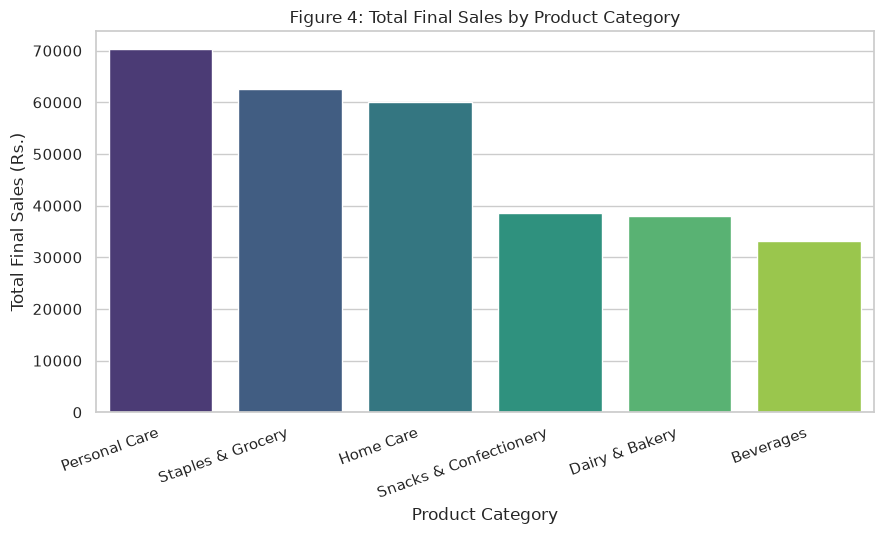

In [47]:
sns.set_theme(style="whitegrid")
cat_sales = df.groupby("Category")["Final_Sales"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 5.5))
sns.barplot(x=cat_sales.index, y=cat_sales.values, hue=cat_sales.index,
            palette="viridis", legend=False)
plt.title("Figure 4: Total Final Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Final Sales (Rs.)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 5: Total Quantity Sold by Category

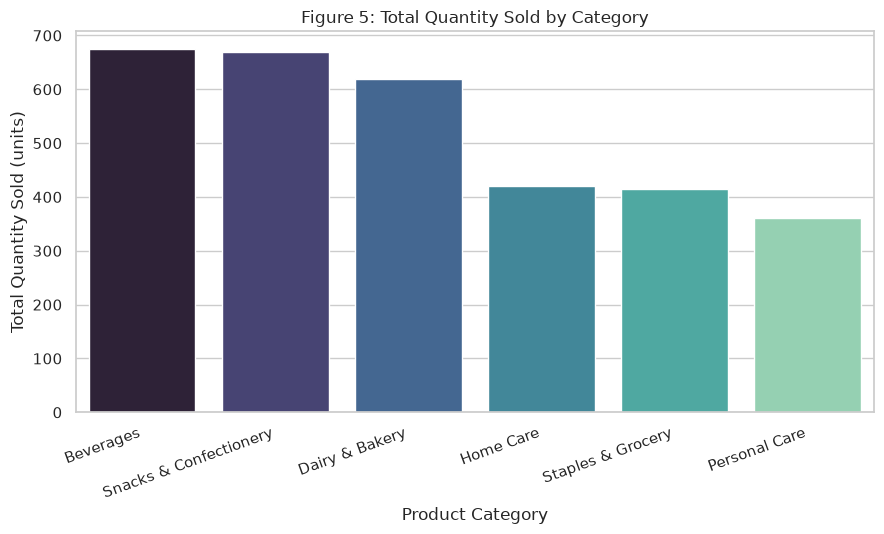

In [48]:
cat_qty = df.groupby("Category")["Quantity"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 5.5))
sns.barplot(x=cat_qty.index, y=cat_qty.values, hue=cat_qty.index,
            palette="mako", legend=False)
plt.title("Figure 5: Total Quantity Sold by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold (units)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 6: Top 10 Products by Final Sales

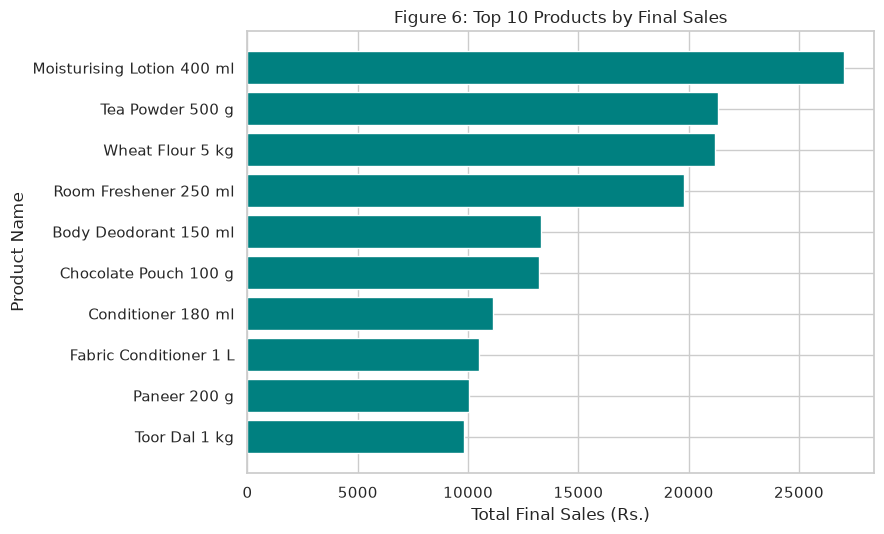

In [49]:
prod_sales = df.groupby("Product_Name")["Final_Sales"].sum().sort_values(ascending=False)
top10 = prod_sales.head(10).sort_values()
plt.figure(figsize=(9, 5.5))
plt.barh(top10.index, top10.values, color="teal")
plt.title("Figure 6: Top 10 Products by Final Sales")
plt.xlabel("Total Final Sales (Rs.)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 7: Bottom 10 Products by Final Sales

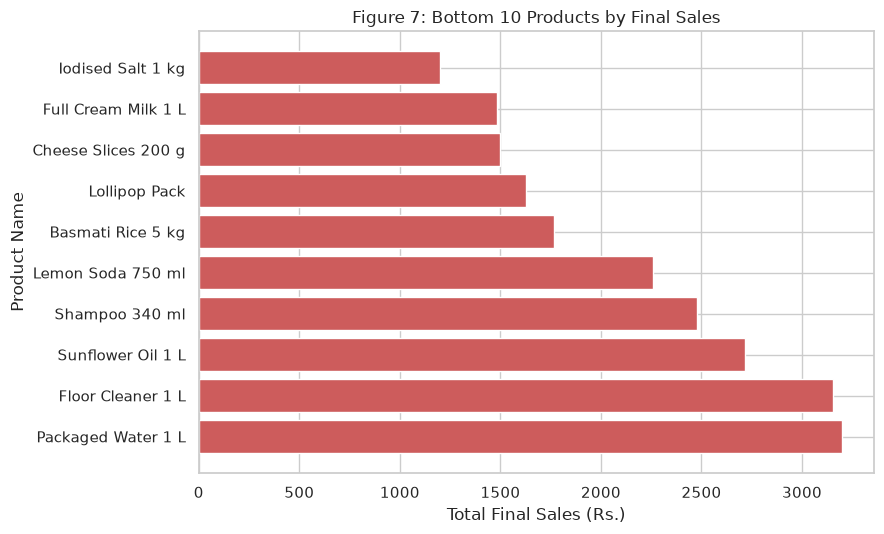

In [50]:
bottom10 = prod_sales.tail(10).sort_values(ascending=False)
plt.figure(figsize=(9, 5.5))
plt.barh(bottom10.index, bottom10.values, color="indianred")
plt.title("Figure 7: Bottom 10 Products by Final Sales")
plt.xlabel("Total Final Sales (Rs.)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 8: Share of Each Category in Total Final Sales (Donut Chart)

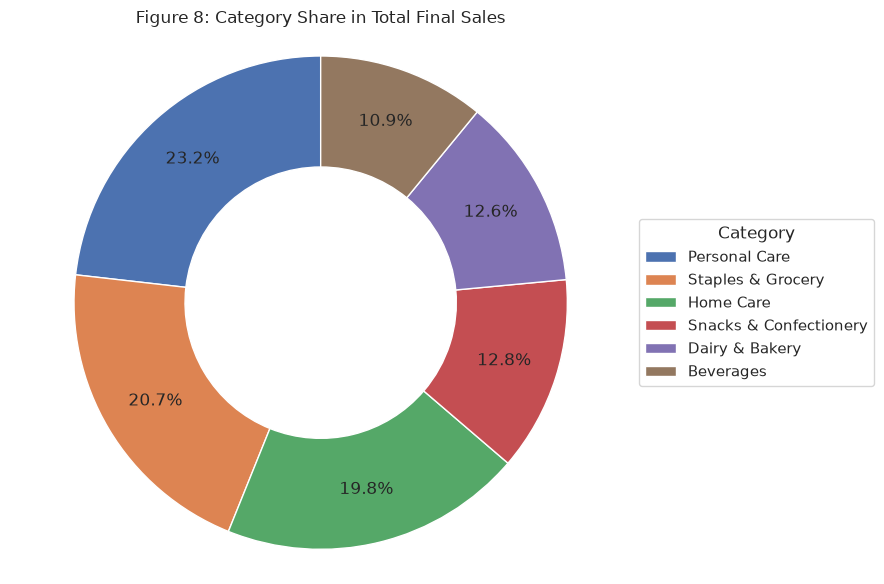

In [51]:
plt.figure(figsize=(9, 6))
plt.pie(cat_sales.values, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
        wedgeprops={"width": 0.45, "edgecolor": "white"})
plt.legend(cat_sales.index, title="Category", loc="center left",
           bbox_to_anchor=(1, 0.5))
plt.title("Figure 8: Category Share in Total Final Sales")
plt.axis("equal")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 9: Distribution of Unit Price

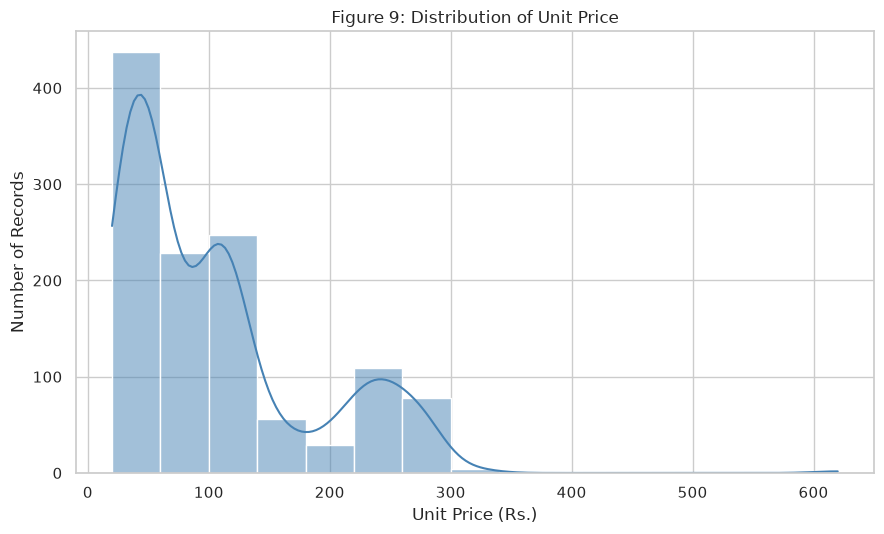

In [52]:
plt.figure(figsize=(9, 5.5))
sns.histplot(df["Unit_Price"], bins=15, kde=True, color="steelblue")
plt.title("Figure 9: Distribution of Unit Price")
plt.xlabel("Unit Price (Rs.)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 10: Distribution of Final Sales

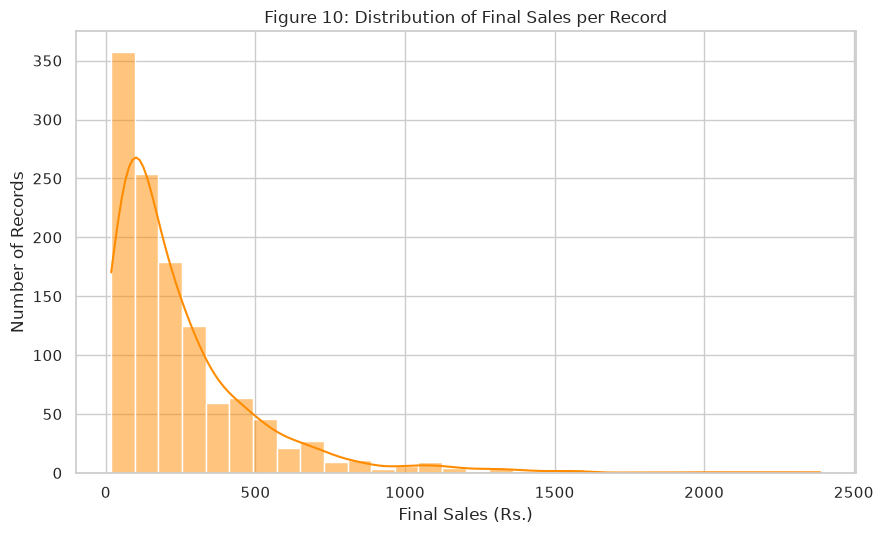

In [53]:
plt.figure(figsize=(9, 5.5))
sns.histplot(df["Final_Sales"], bins=30, kde=True, color="darkorange")
plt.title("Figure 10: Distribution of Final Sales per Record")
plt.xlabel("Final Sales (Rs.)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 11: Boxplot of Final Sales

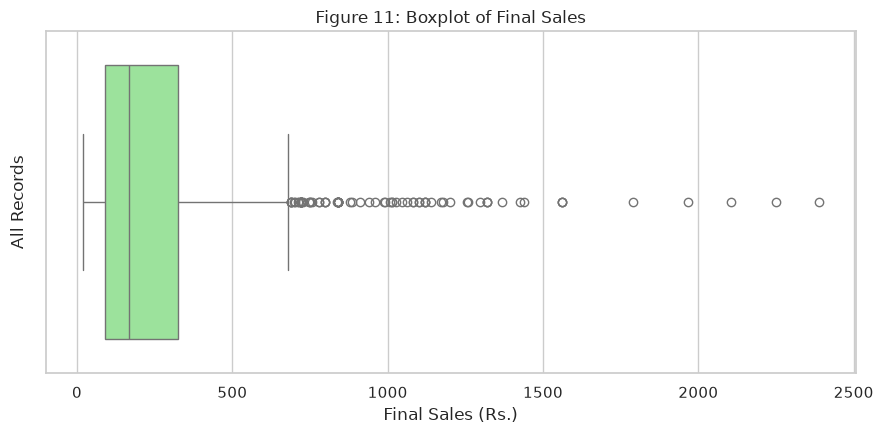

In [54]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(x=df["Final_Sales"], color="lightgreen")
plt.title("Figure 11: Boxplot of Final Sales")
plt.xlabel("Final Sales (Rs.)")
plt.ylabel("All Records")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 12: Boxplot of Unit Price by Category

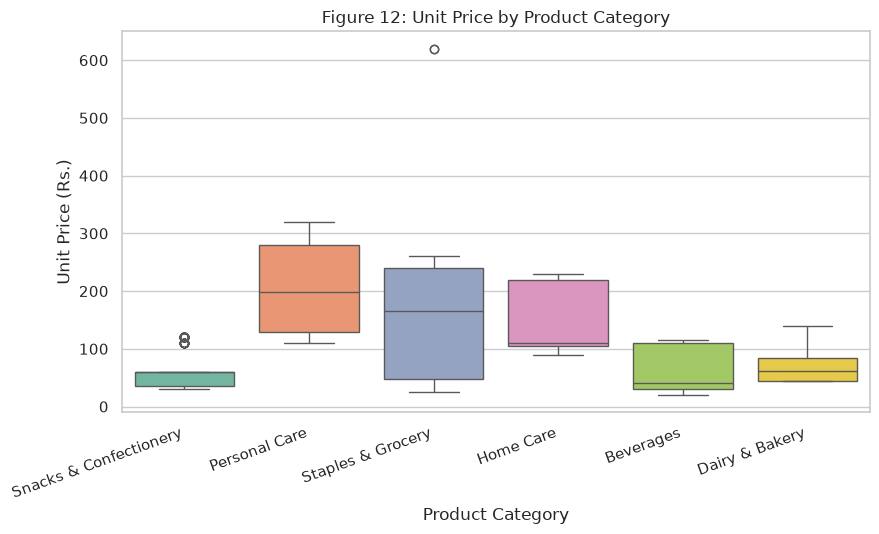

In [55]:
plt.figure(figsize=(9, 5.5))
sns.boxplot(data=df, x="Category", y="Unit_Price", hue="Category",
            palette="Set2", legend=False)
plt.title("Figure 12: Unit Price by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Unit Price (Rs.)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 13: Daily Sales Trend with 7-Day Moving Average

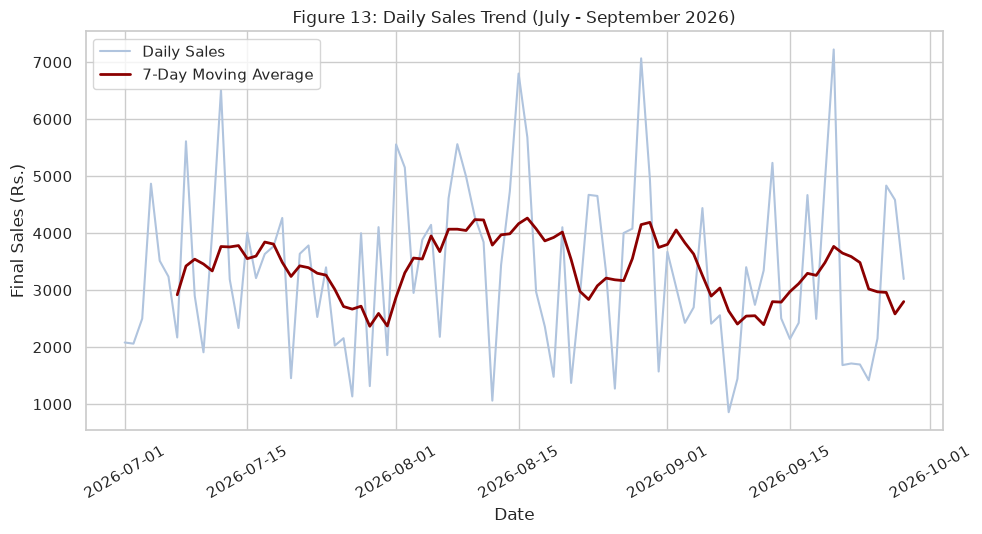

In [56]:
daily = df.groupby("Date")["Final_Sales"].sum()
rolling = daily.rolling(7).mean()
plt.figure(figsize=(10, 5.5))
plt.plot(daily.index, daily.values, color="lightsteelblue", label="Daily Sales")
plt.plot(rolling.index, rolling.values, color="darkred", linewidth=2,
         label="7-Day Moving Average")
plt.title("Figure 13: Daily Sales Trend (July - September 2026)")
plt.xlabel("Date")
plt.ylabel("Final Sales (Rs.)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 14: Monthly Sales Comparison

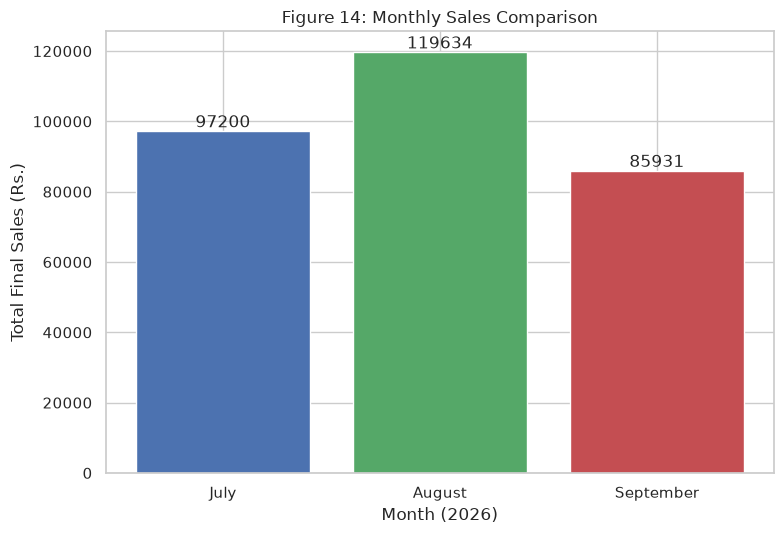

In [57]:
monthly = df.groupby(["Month_No", "Month"])["Final_Sales"].sum().reset_index()
plt.figure(figsize=(8, 5.5))
bars = plt.bar(monthly["Month"], monthly["Final_Sales"],
               color=["#4c72b0", "#55a868", "#c44e52"])
plt.bar_label(bars, fmt="%.0f")
plt.title("Figure 14: Monthly Sales Comparison")
plt.xlabel("Month (2026)")
plt.ylabel("Total Final Sales (Rs.)")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 15: Discount Percentage versus Final Sales

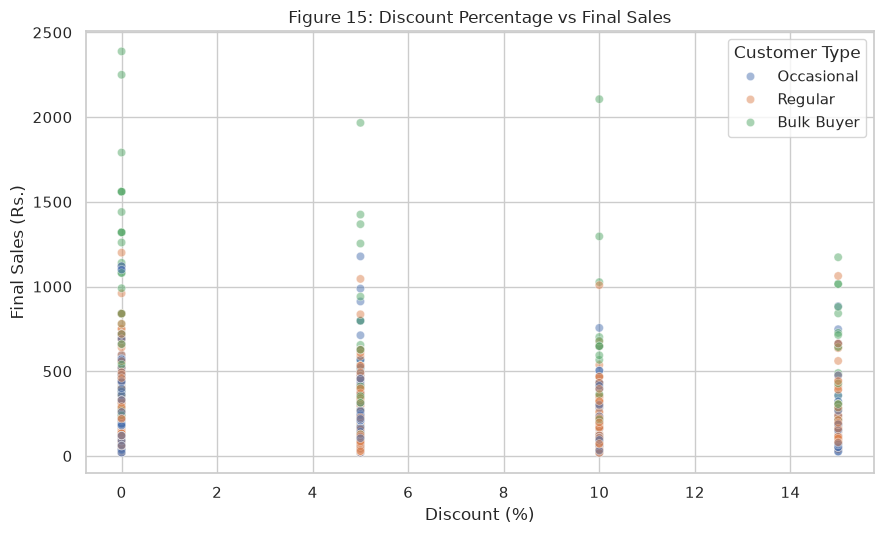

In [58]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="Discount_Percent", y="Final_Sales",
                hue="Customer_Type", alpha=0.5)
plt.title("Figure 15: Discount Percentage vs Final Sales")
plt.xlabel("Discount (%)")
plt.ylabel("Final Sales (Rs.)")
plt.legend(title="Customer Type")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 16: Quantity versus Total Sales

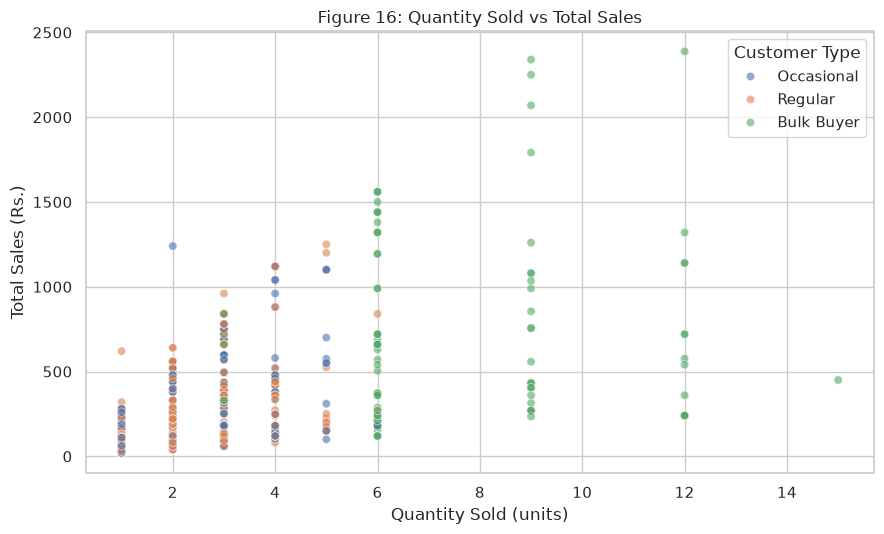

In [59]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="Quantity", y="Total_Sales",
                hue="Customer_Type", alpha=0.6)
plt.title("Figure 16: Quantity Sold vs Total Sales")
plt.xlabel("Quantity Sold (units)")
plt.ylabel("Total Sales (Rs.)")
plt.legend(title="Customer Type")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 17: Payment Method Distribution

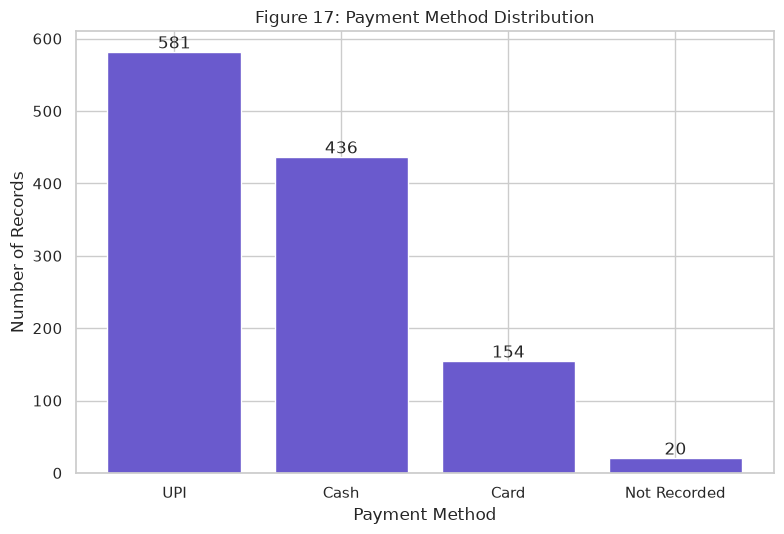

In [60]:
pay_counts = df["Payment_Method"].value_counts()
plt.figure(figsize=(8, 5.5))
bars = plt.bar(pay_counts.index, pay_counts.values, color="slateblue")
plt.bar_label(bars)
plt.title("Figure 17: Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 18: Customer Type Distribution

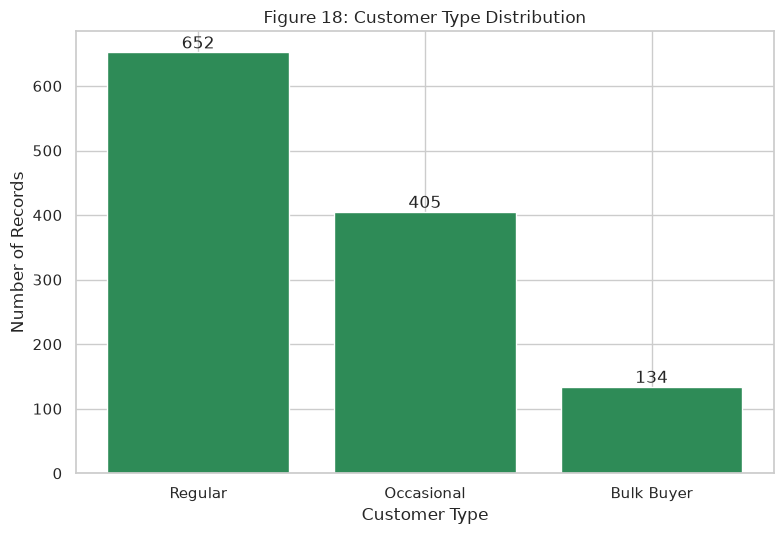

In [61]:
cust_counts = df["Customer_Type"].value_counts()
plt.figure(figsize=(8, 5.5))
bars = plt.bar(cust_counts.index, cust_counts.values, color="seagreen")
plt.bar_label(bars)
plt.title("Figure 18: Customer Type Distribution")
plt.xlabel("Customer Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Section 14: Data Visualization - Figure 19: Correlation Heatmap of Numerical Variables

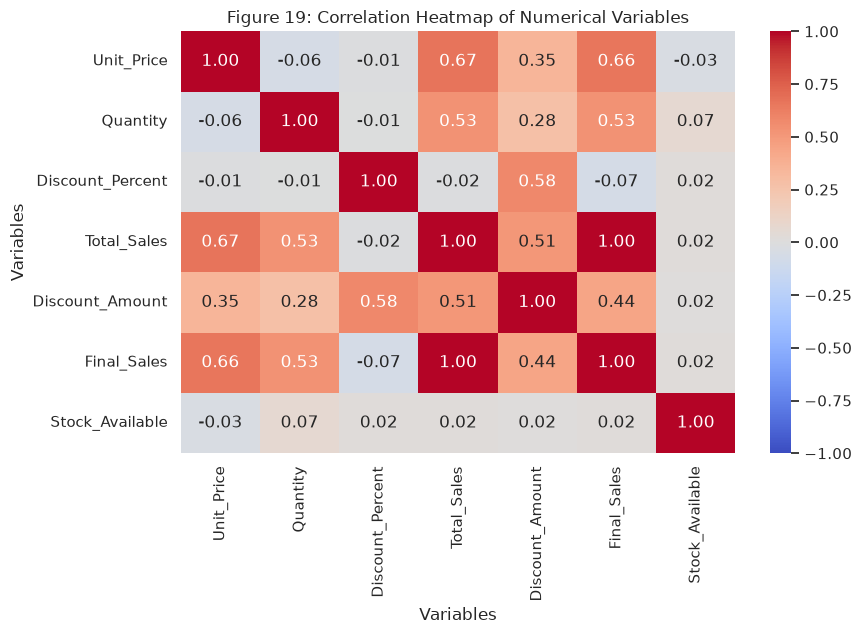

In [62]:
num = df[["Unit_Price", "Quantity", "Discount_Percent", "Total_Sales",
          "Discount_Amount", "Final_Sales", "Stock_Available"]]
plt.figure(figsize=(9, 6.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Figure 19: Correlation Heatmap of Numerical Variables")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()